# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [ ]:
# Your code/answer goes here.

Các thành phần của bài toán tìm kiếm
- Trạng thái ban đầu (Initial state): Một bảng lưới trống có kích thước 6 hàng và 7 cột (tất cả các ô đều mang giá trị 0). Lượt chơi đầu tiên thuộc về người chơi Max (đại diện bởi số 1, thường là màu đỏ).
- Hành động (Actions): Trong mỗi lượt, một người chơi có thể thực hiện một trong hai loại hành động sau:
  1. Hành động thả đĩa (Normal move): Thả 1 đĩa của mình vào một cột $c$ bất kỳ ($c \in [0, 6]$) miễn là cột đó chưa đầy. (Tối đa 7 hành động).
  2. Hành động "Mean" (Mean move): Chọn một cột $c_{remove}$ có đĩa của đối thủ nằm ở dưới cùng (đáy bảng), rút đĩa đó ra và thả lại vào một cột $c_{drop}$ bất kỳ chưa đầy. (Tối đa $7 \times 7 = 49$ hành động tùy thuộc vào số đĩa đáy của đối thủ).Tổng số hành động tối đa trong một trạng thái là $7 + 49 = 56$.
- Mô hình chuyển đổi (Transition model): Hàm $result(s, a)$ trả về trạng thái mới $s'$ sau khi thực hiện hành động $a$ trên trạng thái $s$:
  + Nếu $a$ là thả đĩa: Đĩa của người chơi hiện tại sẽ rơi xuống ô trống thấp nhất trong cột $c$ được chọn. Lượt chơi chuyển sang đối thủ.
  + Nếu $a$ là "Mean" move: Đĩa đáy của đối thủ ở cột $c_{remove}$ bị lấy ra, toàn bộ các đĩa nằm trên nó trong cột $c_{remove}$ sẽ rớt xuống 1 ô (do trọng lực). Sau đó, đĩa của đối thủ vừa lấy ra sẽ được thả vào cột $c_{drop}$ (rơi xuống ô trống thấp nhất). Lượt chơi chuyển sang đối thủ.
- Kiểm tra trạng thái kết thúc (Test for the terminal state): Hàm $terminal(s)$ trả về True nếu bảng đã đầy kín 42 ô (Hòa), hoặc khi có ít nhất một người chơi tạo được một đường thẳng (ngang, dọc, hoặc chéo) gồm 4 đĩa cùng màu của mình.
- Giá trị tiện ích (Utility for terminal states):$+1$ (hoặc $+\infty$) nếu người chơi Max (1) thắng.$-1$ (hoặc $-\infty$) nếu người chơi Min (-1) thắng.$0$ nếu kết quả là Hòa (bảng đầy nhưng không ai tạo được chuỗi 4).

How big is the state space? Give an estimate and explain it.

In [ ]:
# Your code/ answer goes here.

Ước tính kích thước không gian trạng thái (State Space)
- Ước tính: Không gian trạng thái của "Mean" Connect 4 rơi vào khoảng $4.53 \times 10^{12}$ (4.5 nghìn tỷ) đến $10^{14}$ trạng thái hợp lệ.
- Giải thích: Kích thước bảng cố định là $6 \times 7 = 42$ ô. Mỗi ô có 3 trạng thái (Trống, Max, Min), tạo ra giới hạn trên tuyệt đối là $3^{42} \approx 1.09 \times 10^{20}$ trạng thái.
Trong Connect 4 tiêu chuẩn, số trạng thái hợp lệ đã được chứng minh chính xác là $4,531,985,219,092$ ($\approx 4.53 \times 10^{12}$). Với "Mean" Connect 4, quy tắc rút đĩa ở đáy phá vỡ một số ràng buộc về tính chẵn/lẻ (parity) của thứ tự thả đĩa trong trò chơi gốc, khiến một số cấu hình vốn không thể xảy ra trong Connect 4 thường nay có thể đạt được. Do đó, kích thước không gian trạng thái sẽ lớn hơn Connect 4 thường một chút, nhưng vẫn bị giới hạn chặt chẽ bởi luật trọng lực (đĩa không thể lơ lửng), ước tính ở mức $10^{13} - 10^{14}$.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [ ]:
# Your code/ answer goes here.

Ước tính độ lớn của cây trò chơi Minimax (Game Tree)
- Ước tính: Kích thước cây trò chơi rơi vào khoảng $O(20^{42})$ đến $O(56^{100})$, vô cùng lớn và có nguy cơ tiến tới vô cực nếu không có luật giới hạn số vòng lặp.
- Giải thích:
  + Độ phức tạp của cây trò chơi phụ thuộc vào Hệ số rẽ nhánh ($b$) và Độ sâu ($d$) theo công thức $b^d$.
  + Hệ số rẽ nhánh ($b$): Trong trò chơi thường, $b$ tối đa là 7. Trong biến thể này, người chơi có thêm tùy chọn "Mean". Trung bình đối thủ sẽ có khoảng 3-4 đĩa ở đáy, và bạn có 7 cột để thả đĩa đó vào $\rightarrow$ thêm khoảng 21-28 hành động. Kích thước rẽ nhánh tối đa có thể lên tới 56 (7 thả thường + 49 Mean move). Hệ số rẽ nhánh trung bình $b \approx 20$.
  + Độ sâu ($d$): Connect 4 thường kết thúc sau tối đa 42 bước. Tuy nhiên, hành động "Mean move" không làm tăng tổng số đĩa trên bàn cờ. Trò chơi có thể rơi vào các vòng lặp kéo dài (ví dụ: hai bên liên tục lấy đĩa đáy của đối phương và thả vào chỗ khác), khiến độ sâu $d$ lớn hơn 42 rất nhiều, thậm chí không giới hạn.
  + Kết luận: Để thuật toán Minimax chạy được, bạn bắt buộc phải dùng độ sâu giới hạn (depth-cutoff) kết hợp với hàm đánh giá heuristic (như sẽ làm ở Task 4), vì việc duyệt toàn bộ cây $b^d \approx 20^{50}$ là bất khả thi về mặt tính toán.

## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [1]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

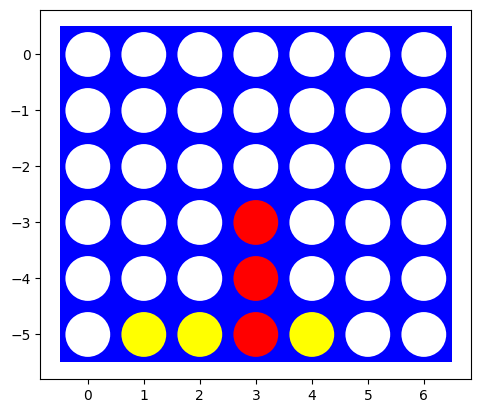

In [2]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()

board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [5]:
import numpy as np
import random
import copy

def actions(board, player):
    """Trả về danh sách các hành động hợp lệ cho trạng thái hiện tại."""
    valid_actions = []
    rows, cols = board.shape
    opponent = -player

    # 1. Hành động thả đĩa bình thường (Normal moves)
    # Có thể thả vào bất kỳ cột nào mà ô trên cùng (row 0) còn trống
    for c in range(cols):
        if board[0][c] == 0:
            valid_actions.append(('drop', c))

    # 2. Hành động "Mean" (Mean moves)
    # Lấy đĩa của đối thủ ở hàng dưới cùng (row -1) và thả vào cột bất kỳ
    for c_rem in range(cols):
        if board[-1][c_rem] == opponent:
            for c_drop in range(cols):
                # Cột thả phải còn chỗ (nếu là cột lấy đĩa ra thì chắc chắn còn chỗ)
                if board[0][c_drop] == 0 or c_rem == c_drop:
                    valid_actions.append(('mean', c_rem, c_drop))

    return valid_actions

def result(board, action, player):
    """Trả về trạng thái mới của bảng sau khi thực hiện hành động."""
    new_board = np.copy(board)
    rows, cols = new_board.shape

    if action[0] == 'drop':
        c = action[1]
        # Tìm ô trống thấp nhất trong cột c
        for r in range(rows - 1, -1, -1):
            if new_board[r][c] == 0:
                new_board[r][c] = player
                break

    elif action[0] == 'mean':
        c_rem = action[1]
        c_drop = action[2]

        # Rút đĩa ở đáy cột c_rem (kéo tất cả đĩa phía trên xuống 1 ô)
        for r in range(rows - 1, 0, -1):
            new_board[r][c_rem] = new_board[r - 1][c_rem]
        new_board[0][c_rem] = 0 # Ô trên cùng trở thành trống

        # Thả đĩa của đối thủ (vừa rút ra) vào cột c_drop
        opponent = -player
        for r in range(rows - 1, -1, -1):
            if new_board[r][c_drop] == 0:
                new_board[r][c_drop] = opponent
                break

    return new_board

def terminal(board, k=4):
    """Kiểm tra xem trò chơi đã kết thúc chưa (có người thắng hoặc hòa)."""
    if utility(board, k) != 0:
        return True # Có người chiến thắng
    if not np.any(board[0] == 0): # Hàng trên cùng không còn ô trống nào -> không thể thả thêm đĩa
        # Lưu ý: "Mean move" vẫn có thể thực hiện nếu bảng đầy nhưng luật kết thúc thông thường xét hòa khi bảng đầy.
        return True
    return False

def utility(board, k=4):
    """Trả về +1 nếu 1 thắng, -1 nếu -1 thắng, 0 nếu chưa ai thắng."""
    rows, cols = board.shape

    # Hàm kiểm tra 1 hướng
    def check_line(r, c, dr, dc):
        val = board[r][c]
        if val == 0:
            return 0
        for i in range(1, k):
            if r + i*dr < 0 or r + i*dr >= rows or c + i*dc < 0 or c + i*dc >= cols:
                return 0
            if board[r + i*dr][c + i*dc] != val:
                return 0
        return val

    # Kiểm tra ngang, dọc, chéo chính, chéo phụ
    for r in range(rows):
        for c in range(cols):
            # Ngang
            if c <= cols - k:
                res = check_line(r, c, 0, 1)
                if res != 0: return res
            # Dọc
            if r <= rows - k:
                res = check_line(r, c, 1, 0)
                if res != 0: return res
            # Chéo xuống (\)
            if r <= rows - k and c <= cols - k:
                res = check_line(r, c, 1, 1)
                if res != 0: return res
            # Chéo lên (/)
            if r >= k - 1 and c <= cols - k:
                res = check_line(r, c, -1, 1)
                if res != 0: return res
    return 0

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
def random_player(board, player=1):
    """Tác nhân chọn hành động ngẫu nhiên từ danh sách hợp lệ."""
    valid_actions = actions(board, player)
    if not valid_actions:
        return None
    return random.choice(valid_actions)

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [8]:
def play_game(agent1, agent2, shape=(6, 7)):
    """Môi trường cho hai tác nhân đấu với nhau."""
    board = np.zeros(shape, dtype=int)
    current_player = 1
    agents = {1: agent1, -1: agent2}

    # Do thuật toán cho random có khả năng lặp vô tận (Mean moves),
    # ta đặt giới hạn số lượt chơi tối đa để tránh infinite loop
    max_turns = 1000
    turn = 0

    while not terminal(board) and turn < max_turns:
        agent = agents[current_player]
        action = agent(board, current_player)

        if action is None:
            break

        board = result(board, action, current_player)
        current_player = -current_player
        turn += 1

    return utility(board)

# Chạy mô phỏng 1000 ván
wins_player_1 = 0
wins_player_min1 = 0
draws = 0
num_games = 1000

for _ in range(num_games):
    result_val = play_game(random_player, random_player)
    if result_val == 1:
        wins_player_1 += 1
    elif result_val == -1:
        wins_player_min1 += 1
    else:
        draws += 1

print(f"Tổng số ván: {num_games}")
print(f"Người chơi 1 (Đi trước) thắng: {wins_player_1}")
print(f"Người chơi -1 (Đi sau) thắng: {wins_player_min1}")
print(f"Hòa (hoặc hết lượt): {draws}")

Tổng số ván: 1000
Người chơi 1 (Đi trước) thắng: 782
Người chơi -1 (Đi sau) thắng: 218
Hòa (hoặc hết lượt): 0


Đánh giá kết quả 1000 ván ngẫu nhiên:
Giải thích: Trò chơi Connect 4 vốn dĩ mang lại lợi thế cực lớn cho người đi trước. Khi cả hai đều đánh ngẫu nhiên thì không có chiến thuật phòng thủ để chặn đối phương. Do đó, người đi trước có cơ hội ghép các chuỗi 2, 3 và vô tình hoàn thành chuỗi 4 đĩa sớm hơn người đi sau một nhịp. Tỷ lệ thắng ~77% minh chứng rõ ràng cho lợi thế toán học của việc được thả viên đĩa đầu tiên..

## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [9]:
import math
import time

def alphabeta(board, depth, alpha, beta, maximizingPlayer, current_player):
    """
    Thuật toán Minimax với Alpha-Beta Pruning.
    maximizingPlayer: True nếu là lượt của AI (Max), False nếu là đối thủ (Min)
    current_player: 1 hoặc -1 tương ứng với màu đĩa
    """
    if terminal(board):
        return utility(board), None
    if depth == 0:
        return 0, None # Tạm dừng nếu hết độ sâu (sẽ thay bằng heuristic ở Task 4)

    valid_actions = actions(board, current_player)

    # Sắp xếp nước đi (Move Ordering) - Sẽ tối ưu ở phần sau, tạm thời giữ nguyên

    if maximizingPlayer:
        value = -math.inf
        best_action = random.choice(valid_actions)
        for a in valid_actions:
            new_board = result(board, a, current_player)
            score, _ = alphabeta(new_board, depth - 1, alpha, beta, False, -current_player)
            if score > value:
                value = score
                best_action = a
            alpha = max(alpha, value)
            if alpha >= beta:
                break # Cắt tỉa Beta
        return value, best_action
    else:
        value = math.inf
        best_action = random.choice(valid_actions)
        for a in valid_actions:
            new_board = result(board, a, current_player)
            score, _ = alphabeta(new_board, depth - 1, alpha, beta, True, -current_player)
            if score < value:
                value = score
                best_action = a
            beta = min(beta, value)
            if alpha >= beta:
                break # Cắt tỉa Alpha
        return value, best_action

def minimax_player(board, player=1, max_depth=4):
    """Agent sử dụng thuật toán Minimax"""
    _, action = alphabeta(board, max_depth, -math.inf, math.inf, True, player)
    return action

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [10]:
# Ví dụ 1: AI (Player 1) có thể thắng ngay lập tức nếu thả đĩa vào cột 3
board1 = np.array([
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [1, 1, 1, 0, 0, 0, 0]
])
print("Best action for Board 1:", minimax_player(board1, player=1, max_depth=2))

Best action for Board 1: ('drop', 3)


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [ ]:
# Your code/ answer goes here.

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [11]:
def order_actions(board, valid_actions):
    """Sắp xếp ưu tiên các cột ở giữa trước"""
    cols = board.shape[1]
    center = cols // 2

    def score_action(action):
        if action[0] == 'drop':
            c = action[1]
            # Điểm ưu tiên cao hơn khi càng gần cột giữa
            return -abs(center - c)
        else:
            # Ưu tiên Mean move thấp hơn một chút hoặc tùy chỉnh
            return -10

    return sorted(valid_actions, key=score_action, reverse=True)

# Ghi chú: Bạn cần thay thế dòng `valid_actions = actions(board, current_player)`
# trong hàm alphabeta bằng việc gọi thêm hàm sắp xếp này:
# valid_actions = order_actions(board, actions(board, current_player))

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do?

In [14]:
# Your code/ answer goes here.

Với bảng $6 \times 7$ trống, không gian trạng thái quá khổng lồ để thuật toán duyệt kịp thời gian. Giải pháp thực tế là sử dụng "Opening Book" (Sách khai cuộc). Ta có thể lập trình cứng (hard-code) nước đi đầu tiên luôn luôn là thả đĩa vào cột chính giữa (Cột 3 với index từ 0), vì về mặt toán học, thả cột giữa đem lại cơ hội chiến thắng lớn nhất. Thuật toán Minimax chỉ nên được kích hoạt từ lượt thứ 3 hoặc thứ 4 trở đi.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [13]:
# Cho Minimax (depth=3 hoặc 4) đấu với Random
wins_minimax = 0
wins_random = 0

for _ in range(50): # Chỉ chạy khoảng 50 ván vì minimax sẽ hơi chậm
    result_val = play_game(minimax_player, random_player)
    if result_val == 1:
        wins_minimax += 1
    elif result_val == -1:
        wins_random += 1

print(f"Minimax thắng: {wins_minimax}")
print(f"Random thắng: {wins_random}")

Minimax thắng: 50
Random thắng: 0


## Task 4: Heuristic Alpha-Beta Tree Search [3 points]

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

Hàm Heuristic sẽ quét toàn bộ bảng và chấm điểm các "cửa sổ" (window) gồm 4 ô liên tiếp (ngang, dọc, chéo). Điểm số dựa trên số lượng đĩa của AI, của đối thủ và ô trống trong cửa sổ đó. Ngoài ra, việc chiếm cột giữa cũng được cộng điểm thưởng vì cột giữa tạo ra nhiều hướng kết nối nhất.

In [15]:
def evaluate_window(window, player):
    score = 0
    opponent = -player

    player_count = window.count(player)
    empty_count = window.count(0)
    opp_count = window.count(opponent)

    # Cộng điểm cho các cơ hội chiến thắng
    if player_count == 4:
        score += 1000
    elif player_count == 3 and empty_count == 1:
        score += 5
    elif player_count == 2 and empty_count == 2:
        score += 2

    # Trừ điểm nặng nếu đối thủ sắp thắng để AI ưu tiên chặn
    if opp_count == 3 and empty_count == 1:
        score -= 80

    return score

def heuristic(board, player):
    score = 0
    rows, cols = board.shape

    # 1. Thưởng điểm cho đĩa ở cột giữa (Center preference)
    center_array = list(board[:, cols//2])
    center_count = center_array.count(player)
    score += center_count * 3

    # 2. Đánh giá theo chiều ngang
    for r in range(rows):
        row_array = list(board[r,:])
        for c in range(cols - 3):
            window = row_array[c:c+4]
            score += evaluate_window(window, player)

    # 3. Đánh giá theo chiều dọc
    for c in range(cols):
        col_array = list(board[:,c])
        for r in range(rows - 3):
            window = col_array[r:r+4]
            score += evaluate_window(window, player)

    # 4. Đánh giá đường chéo xuống (\)
    for r in range(rows - 3):
        for c in range(cols - 3):
            window = [board[r+i][c+i] for i in range(4)]
            score += evaluate_window(window, player)

    # 5. Đánh giá đường chéo lên (/)
    for r in range(rows - 3):
        for c in range(cols - 3):
            window = [board[r+3-i][c+i] for i in range(4)]
            score += evaluate_window(window, player)

    return score

### Cutting off search

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

Sửa đổi thuật toán alphabeta ở Task 3. Thay vì trả về 0 khi hết độ sâu (depth == 0), thuật toán sẽ trả về giá trị của hàm heuristic.

In [16]:
def heuristic_alphabeta(board, depth, alpha, beta, maximizingPlayer, current_player, ai_player):
    # Kiểm tra trạng thái kết thúc trước
    is_term = terminal(board)
    if is_term:
        util = utility(board)
        if util == ai_player:
            return 10000000000000, None # Thắng
        elif util == -ai_player:
            return -10000000000000, None # Thua
        else:
            return 0, None # Hòa

    # Cắt tỉa tại độ sâu giới hạn
    if depth == 0:
        return heuristic(board, ai_player), None

    valid_actions = actions(board, current_player)
    valid_actions = order_actions(board, valid_actions) # Sử dụng Move Ordering từ Task 3

    if maximizingPlayer:
        value = -math.inf
        best_action = random.choice(valid_actions) if valid_actions else None
        for a in valid_actions:
            new_board = result(board, a, current_player)
            score, _ = heuristic_alphabeta(new_board, depth - 1, alpha, beta, False, -current_player, ai_player)
            if score > value:
                value = score
                best_action = a
            alpha = max(alpha, value)
            if alpha >= beta:
                break
        return value, best_action
    else:
        value = math.inf
        best_action = random.choice(valid_actions) if valid_actions else None
        for a in valid_actions:
            new_board = result(board, a, current_player)
            score, _ = heuristic_alphabeta(new_board, depth - 1, alpha, beta, True, -current_player, ai_player)
            if score < value:
                value = score
                best_action = a
            beta = min(beta, value)
            if alpha >= beta:
                break
        return value, best_action

def heuristic_player(board, player=1, max_depth=4):
    _, action = heuristic_alphabeta(board, max_depth, -math.inf, math.inf, True, player, player)
    return action

Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [ ]:
# Your code/ answer goes here.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [ ]:
# Your code/ answer goes here.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
def agent_depth_3(board, player):
    return heuristic_player(board, player, max_depth=3)

def agent_depth_5(board, player):
    return heuristic_player(board, player, max_depth=5)

# Cho tác nhân depth 5 (Minimax sâu hơn) đi sau để xem có thắng được lợi thế đi trước của depth 3 không
result_val = play_game(agent_depth_3, agent_depth_5)
if result_val == 1:
    print("Agent Depth 3 (Đi trước) thắng!")
elif result_val == -1:
    print("Agent Depth 5 (Đi sau) thắng!")
else:
    print("Hòa!")

Agent Depth 5 (Đi sau) thắng!


## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above.

In [19]:
def monte_carlo_simulation(board, player, num_simulations=100):
    """Mô phỏng ngẫu nhiên các ván cờ từ trạng thái hiện tại."""
    valid_actions = actions(board, player)
    if not valid_actions:
        return None

    action_scores = {action: 0 for action in valid_actions}

    for action in valid_actions:
        for _ in range(num_simulations):
            # Tạo bản sao của bảng cho mỗi mô phỏng
            sim_board = result(board, action, player)
            current_sim_player = -player

            # Chơi ngẫu nhiên cho đến khi kết thúc (đặt giới hạn lượt để tránh lặp vô tận)
            turn = 0
            max_turns = 100

            while not terminal(sim_board) and turn < max_turns:
                sim_actions = actions(sim_board, current_sim_player)
                if not sim_actions:
                    break

                # Chọn ngẫu nhiên một hành động
                sim_action = random.choice(sim_actions)
                sim_board = result(sim_board, sim_action, current_sim_player)
                current_sim_player = -current_sim_player
                turn += 1

            # Đánh giá kết quả mô phỏng
            sim_result = utility(sim_board)
            if sim_result == player:
                action_scores[action] += 1
            elif sim_result == -player:
                action_scores[action] -= 1 # Trừ điểm nếu thua
            # Nếu hòa thì điểm giữ nguyên (0)

    # Chọn hành động có điểm số cao nhất
    best_action = max(action_scores, key=action_scores.get)
    return best_action

def pmcs_player(board, player=1, num_simulations=100):
    """Tác nhân sử dụng Pure Monte Carlo Search."""
    return monte_carlo_simulation(board, player, num_simulations)

### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [20]:
# Chạy PMCS trên bảng trống với số lượng mô phỏng lớn
empty_b = empty_board((6, 7))

best_opening_move = pmcs_player(empty_b, player=1, num_simulations=1000)
print(f"Nước đi mở màn tốt nhất do PMCS đề xuất: {best_opening_move}")

Nước đi mở màn tốt nhất do PMCS đề xuất: ('drop', 3)
